# Homework 4: Evaluation Metrics for Classification

In [14]:
# imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.style.use('ggplot')

In [15]:
#!wget https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv

In [16]:
# Load dataset
df = pd.read_csv('course_lead_scoring_2026.csv')
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [17]:
# Checking for missing values
df.isnull().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [18]:
# categorical features
m_categorical_cols = ['lead_source', 'industry', 'employment_status', 'location']

# numrical features
m_numerical_cols = ['annual_income', 'lead_score', 'number_of_courses_viewed']

# Filling the missing values
df[m_categorical_cols] = df[m_categorical_cols].fillna('NA')
df[m_numerical_cols] = df[m_numerical_cols].fillna(0.0)

# Check if there is still missing values
df.isnull().sum()

lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64

In [19]:
from sklearn.model_selection import train_test_split

In [ ]:
# Splitting train/val/test
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

**Question 1: ROC AUC feature importance**

ROC AUC could also be used to evaluate feature importance of numerical variables.

Let's do that

- For each numerical variable, use it as score (aka prediction) and compute the AUC with the y variable as ground truth.
- Use the training dataset for that
If your AUC is < 0.5, invert this variable by putting "-" in front

(e.g. -df_train['balance'])

AUC can go below 0.5 if the variable is negatively correlated with the target variable. You can change the direction of the correlation by negating this variable - then negative correlation becomes positive.

Which numerical variable (among the following 4) has the highest AUC?

- `lead_score`
- `number_of_courses_viewed`
- `interaction_count`
- `annual_income`

In [24]:
# numerical_variables
numerical_cols = ['annual_income', 'lead_score', 'number_of_courses_viewed', 'interaction_count']

In [38]:
from sklearn.metrics import roc_auc_score

for col in numerical_cols:
    # target
    y_pred = df_train[col]
    y_test = df_train['converted']

    # roc auc
    auc_score = roc_auc_score(y_test, y_pred)

    # inversion
    if auc_score < 0.5:
        auc_score = roc_auc_score(y_test, -y_pred)

    print(f"auc score for {col:<30}: {auc_score}")

auc score for annual_income                 : 0.6081977776250831
auc score for number_of_courses_viewed      : 0.7229894623989618
auc score for interaction_count             : 0.7649203047563227
auc score for lead_score                    : 0.7882254810906102


The `lead_score` feature has the highest AUC score.

**Question 2: Training the model**

Apply one-hot-encoding using DictVectorizer and train the logistic regression with these parameters:

```python
LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
```

What's the AUC of this model on the validation dataset? (round to 3 digits)

- 0.532
- 0.632
- 0.732
- 0.832

In [37]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

# Categorical columns
categorical_cols = ['lead_source', 'industry', 'employment_status', 'location']

# Numerical columns
numerical_cols = ['annual_income', 'number_of_courses_viewed', 'interaction_count', 'lead_score']

# Train set
X_train = df_train.drop(columns='converted')
y_train = df_train['converted']

# Validation set
X_val = df_val.drop(columns='converted')
y_val = df_val['converted']

# Test set
X_test = df_test.drop(columns='converted')
y_test = df_test['converted']

# Pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ('categorical', OneHotEncoder(handle_unknown='ignore'), categorical_cols)
    ],
    remainder='passthrough'
)


# Encoding the training set
X_train_encoded = preprocessor.fit_transform(X_train)

# Encoding the validation set
X_val_encoded = preprocessor.transform(X_val)

# Encoding the test set
X_test_encoded = preprocessor.transform(X_test)

In [39]:
from sklearn.linear_model import LogisticRegression

# model
classifier = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)

# Training
classifier.fit(X_train_encoded, y_train)

,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalt

In [43]:
# AUC score
y_pred = classifier.predict(X_val_encoded)

auc_score = roc_auc_score(y_val, y_pred)

print(f"auc score = {round(auc_score, 3)}")

auc score = 0.598


**Question 3: Precision and Recall**

Now let's compute precision and recall for our model.

- Evaluate the model on all thresholds from 0.0 to 1.0 with step 0.01
- For each threshold, compute precision and recall
- Plot them

At which threshold precision and recall curves intersect? Ignore thresholds at which both metrics are zero, and choose the threshold with the smallest absolute difference between precision and recall.

- 0.43
- 0.63
- 0.73
- 0.83

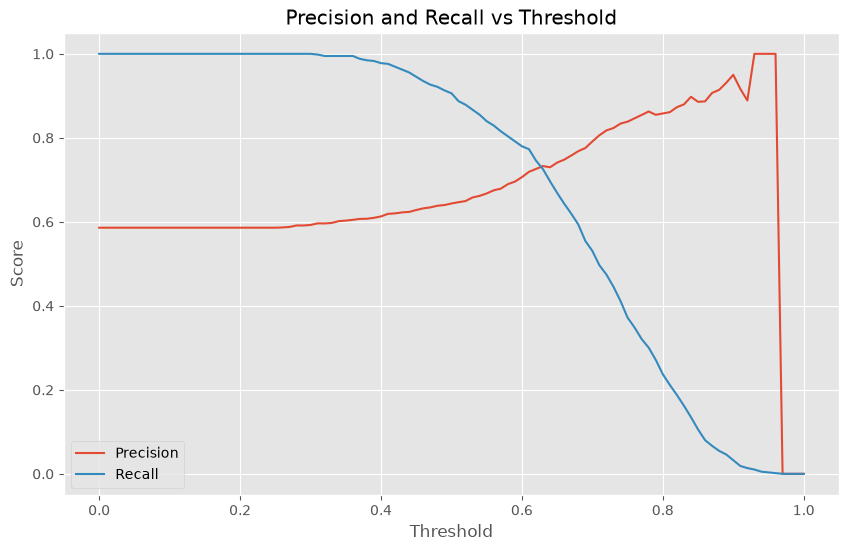

In [47]:
from sklearn.metrics import precision_score, recall_score

# Model's predictions
y_proba = classifier.predict_proba(X_val_encoded)[:, 1]

# All thresholds
thresholds = np.arange(0.0, 1.01, 0.01)

# metrics
precisions = []
recalls = []

# Loop in order to compute the metrics
for threshold in thresholds:
    y_pred = (y_proba >= threshold).astype(int)

    precisions.append(precision_score(y_val, y_pred, zero_division=0))
    recalls.append(recall_score(y_val, y_pred, zero_division=0))

# Visulizations
plt.figure(figsize=(10, 6))
plt.plot(thresholds, precisions, label='Precision')
plt.plot(thresholds, recalls, label='Recall')

plt.xlabel('Threshold')
plt.ylabel('Score')
plt.title('Precision and Recall vs Threshold')
plt.legend()
plt.grid(True)
plt.show()

In 0.63, the precision and the recall intersect.

**Question 4: F1 score**

Precision and recall are conflicting - when one grows, the other goes down. That's why they are often combined into the F1 score - a metrics that takes into account both

This is the formula for computing F1:
$$F_1 = 2 \cdot \cfrac{P \cdot R}{P + R}$$

Where $P$ is precision and $R$ is recall.

Let's compute F1 for all thresholds from 0.0 to 1.0 with increment 0.01

At which threshold F1 is maximal?

- 0.21
- 0.41
- 0.61
- 0.81

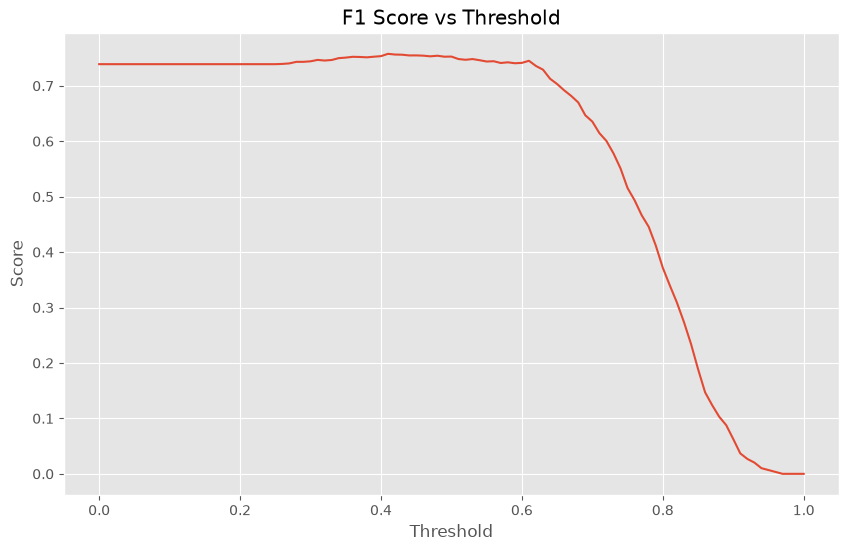

In [54]:
from sklearn.metrics import f1_score

# Model's predictions
y_proba = classifier.predict_proba(X_val_encoded)[:, 1]

# All thresholds
thresholds = np.arange(0.0, 1.01, 0.01)

# metrics
f1_scores = []

# Loop in order to compute the metrics
for threshold in thresholds:
    y_pred = (y_proba >= threshold).astype(int)

    f1_scores.append(f1_score(y_val, y_pred, zero_division=0))

# Visulizations
plt.figure(figsize=(10, 6))
plt.plot(thresholds, f1_scores)

plt.xlabel('Threshold')
plt.ylabel('Score')
plt.title('F1 Score vs Threshold')
plt.grid(True)
plt.show()

**Question 5: 5-Fold CV**

Use the KFold class from Scikit-Learn to evaluate our model on 5 different folds:

```python
KFold(n_splits=5, shuffle=True, random_state=1)
```

- Iterate over different folds of df_full_train
- Split the data into train and validation
- Train the model on train with these parameters: LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
- Use AUC to evaluate the model on validation

How large is standard deviation of the scores across different folds?

- 0.001
- 0.007
- 0.013
- 0.060

In [56]:
from sklearn.model_selection import KFold

kf = KFold(n_splits=5, shuffle=True, random_state=1)

aucs = []

for train_idx, val_idx in kf.split(df_full_train):

    # Split into train and validation
    df_train = df_full_train.iloc[train_idx]
    df_val = df_full_train.iloc[val_idx]

    # Separate features and target
    X_train = df_train.drop(columns='converted')
    y_train = df_train['converted']

    X_val = df_val.drop(columns='converted')
    y_val = df_val['converted']

    # Create a new preprocessor for this fold
    preprocessor = ColumnTransformer(
        transformers=[
            ('categorical', OneHotEncoder(handle_unknown='ignore'), categorical_cols)
        ],
        remainder='passthrough'
    )

    # Encode the data
    X_train_encoded = preprocessor.fit_transform(X_train)
    X_val_encoded = preprocessor.transform(X_val)

    # Train the model
    model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)

    model.fit(X_train_encoded, y_train)

    # Predict probabilities
    y_pred = model.predict_proba(X_val_encoded)[:, 1]

    # Evaluate AUC
    auc = roc_auc_score(y_val, y_pred)
    aucs.append(auc)

    print(f"AUC: {auc:.4f}")

print(f"\nMean AUC: {np.mean(aucs):.4f}")
print(f"Standard deviation: {np.std(aucs):.4f}")


AUC: 0.7306
AUC: 0.7296
AUC: 0.7363
AUC: 0.7412
AUC: 0.7209

Mean AUC: 0.7317
Standard deviation: 0.0069


**Question 6: Hyperparameter Tuning**

Now let's use 5-Fold cross-validation to find the best parameter C

- Iterate over the following C values: [0.000001, 0.001, 1]
- Initialize KFold with the same parameters as previously
- Use these parameters for the model: LogisticRegression(solver='liblinear', C=C, max_iter=1000)
- Compute the mean ROC AUC as well as the std (round the mean and std to 3 decimal digits).

Which C leads to the best mean ROC AUC?

- 0.000001
- 0.001
- 1

In [57]:
C_values = [0.000001, 0.001, 1]

for C in C_values:
    aucs = []

    for train_idx, val_idx in kf.split(df_full_train):
        # Split the data
        df_train = df_full_train.iloc[train_idx]
        df_val = df_full_train.iloc[val_idx]

        X_train = df_train.drop(columns='converted')
        y_train = df_train['converted']

        X_val = df_val.drop(columns='converted')
        y_val = df_val['converted']

        # Preprocessing
        preprocessor = ColumnTransformer(
            transformers=[
                ('categorical', OneHotEncoder(handle_unknown='ignore'), categorical_cols)
            ],
            remainder='passthrough'
        )

        X_train_encoded = preprocessor.fit_transform(X_train)
        X_val_encoded = preprocessor.transform(X_val)

        # Train model with current C
        model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
        model.fit(X_train_encoded, y_train)

        # Evaluate AUC
        y_pred = model.predict_proba(X_val_encoded)[:, 1]
        aucs.append(roc_auc_score(y_val, y_pred))

    print(
        f"C={C}: mean AUC={np.mean(aucs):.3f}, "
        f"std={np.std(aucs):.3f}"
    )


C=1e-06: mean AUC=0.617, std=0.019
C=0.001: mean AUC=0.749, std=0.010
C=1: mean AUC=0.732, std=0.007


---